# OPTIMA tutorial

**OPTIMA** (*Optimizing Data Augmentation through Bayesian Model Selection*, ICLR 2026) treats the
parameters φ of an augmentation distribution p(γ | φ) as latent variables of the model and learns
them jointly with the network, in one training run, by maximising a variational objective.

![OPTIMA diagram](../docs/figures/optima_diagram.svg)

This notebook runs on a CPU in a couple of minutes. It covers:

1. the augmenter API on a toy regression problem;
2. the two objectives in this repository and how they behave differently;
3. writing your own learnable augmentation;
4. a small image classifier with a Bayesian last layer, and its calibration metrics.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn

import optima
from optima import (
    AffineAugmenter,
    BayesianLinear,
    GaussianShift,
    NoAugmentation,
    OptimaObjective,
    categorical_log_likelihood,
    gaussian_log_likelihood,
    optima_step,
    train_epoch,
)
from optima.augmenters import AugmentedBatch, Augmenter
from optima.hyperparameter import HyperParameter
from optima.metrics import (
    accuracy,
    expected_calibration_error,
    mc_predict,
    negative_log_likelihood,
)

BLUE, ORANGE, INK_2 = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "lines.linewidth": 2})
torch.manual_seed(0)
print("optima", optima.__version__)

optima 0.1.0


## 1. The augmenter API

An augmenter is an `nn.Module` that holds its learnable hyperparameters φ as `HyperParameter`
objects and returns an `AugmentedBatch`. `GaussianShift` adds γ ~ N(μ, σ²) to the inputs, with
learnable μ and σ.

In [2]:
def make_data(n, generator):
    x = torch.rand(n, 1, generator=generator) * 6 - 3
    noise = 0.2 * torch.randn(n, 1, generator=generator)
    noise = noise + 0.15 * torch.sin(x) * torch.randn(n, 1, generator=generator)
    return x, torch.sin(2 * x) + 0.5 * torch.cos(3 * x) + noise

g = torch.Generator().manual_seed(0)
x_train, y_train = make_data(50, g)
x_test, y_test = make_data(1000, g)

aug = GaussianShift(init_std=0.1)            # variational q(phi) by default
batch = aug(x_train[:4], y_train[:4])
print("inputs   ", x_train[:4].squeeze().tolist())
print("augmented", batch.x.squeeze().tolist())
print("hyperparameters:", {k: v.tolist() for k, v in aug.hyperparameters().items()})
print("KL(q(phi) || p(phi)) =", aug.kl().item())

inputs    [-0.022460460662841797, 1.609330654144287, -2.469135284423828, -2.2078170776367188]
augmented [-0.07993948459625244, 1.8186296224594116, -2.42035174369812, -2.18953275680542]
hyperparameters: {'std': 0.09999999403953552, 'mean': 0.0}
KL(q(phi) || p(phi)) = 2.125732421875


## 2. Two objectives

**The augmented ELBO (Eq. 7 of the paper)** puts a prior p(φ) on the augmentation parameters:

$$\mathcal{L} = \sum_i \mathbb{E}\big[\log p(y_i \mid T_{\gamma_i}(x_i), \theta)\big]
 - \mathrm{KL}(q(\theta)\,\|\,p(\theta)) - \mathrm{KL}(q(\phi)\,\|\,p(\phi)).$$

`OptimaObjective` computes its negative, per training example (KL terms divided by N), and
`optima_step` runs one forward pass.

**The γ-prior objective** is what the paper's experiments use (Sec. 5.1, App. F.2). It puts a
prior directly on the transformation, γ ~ N(0, τ²), and penalises
KL(N(μ, σ²) ‖ N(0, τ²)) with the full weight against a mean-reduced loss
(`GaussianShift.kl_to_gamma_prior`). It is an exact ELBO for a model with a per-example latent
shift, and its optimum is σ = τ.

The two behave very differently. With a flexible network trained on 50 points, the data
term always prefers *less* augmentation, because the network fits the training points better
without noise. Under Eq. 7 nothing stops σ from shrinking. Under the γ-prior objective, the
prior holds σ near τ.

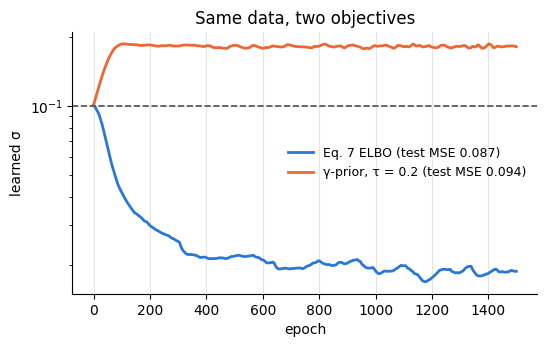

final sigma: ELBO 0.0189, gamma prior 0.1818


In [3]:
def mlp():
    return nn.Sequential(nn.Linear(1, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(),
                         nn.Linear(64, 1))

def fit(kind, epochs=1500, seed=0):
    torch.manual_seed(seed)
    model = mlp()
    aug = GaussianShift(init_std=0.1, mode="variational" if kind == "elbo" else "map")
    opt = torch.optim.Adam([{"params": model.parameters(), "lr": 1e-2},
                            {"params": aug.parameters(), "lr": 1e-2}])
    objective = OptimaObjective(num_train=len(x_train))
    trace = []
    for _ in range(epochs):
        if kind == "elbo":
            loss = optima_step(model, aug, objective, x_train, y_train,
                               lambda p, t: gaussian_log_likelihood(p, t, 0.25)).loss
        else:
            mse = nn.functional.mse_loss(model(aug(x_train, y_train).x), y_train)
            loss = mse + aug.kl_to_gamma_prior(0.2)
        opt.zero_grad()
        loss.backward()
        opt.step()
        trace.append(aug.std.value.item())
    with torch.no_grad():
        test_mse = nn.functional.mse_loss(model(x_test), y_test).item()
    return trace, test_mse

elbo_trace, elbo_mse = fit("elbo")
gp_trace, gp_mse = fit("gamma_prior")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(elbo_trace, color=BLUE, label=f"Eq. 7 ELBO (test MSE {elbo_mse:.3f})")
ax.plot(gp_trace, color=ORANGE, label=f"γ-prior, τ = 0.2 (test MSE {gp_mse:.3f})")
ax.axhline(0.1, color=INK_2, ls="--", lw=1.2)
ax.set(xlabel="epoch", ylabel="learned σ", yscale="log", title="Same data, two objectives")
ax.legend(frameon=False, fontsize=9)
plt.show()
print(f"final sigma: ELBO {elbo_trace[-1]:.4f}, gamma prior {gp_trace[-1]:.4f}")

Under Eq. 7 the learned σ collapses toward zero; under the γ-prior objective it stays close
to τ. Neither result says σ ≈ 0.18 is optimal for the test set; the README's
"Reproducibility notes" section discusses this. To learn augmentation *from the data*
under Eq. 7, the objective needs an Occam factor over θ (a posterior over the network
weights, Algorithm 1), which a point estimate of θ does not provide.

## 3. Writing your own augmentation

Subclass `Augmenter`, store each learnable hyperparameter as a `HyperParameter`, and return an
`AugmentedBatch`. If the sample is differentiable in φ, gradients are pathwise. For discrete
samples, set `reparameterized = False` and return `log_prob`; `OptimaObjective` then adds a
REINFORCE gradient (see `TokenDropout`).

Here is a learnable intensity scaling, x ↦ x·exp(γ) with γ ~ N(0, σ²):

In [4]:
class RandomScaling(Augmenter):
    def __init__(self, init_std=0.1, prior_std=1.0, mode="variational"):
        super().__init__()
        self.std = HyperParameter(init_std, transform="exp", prior_std=prior_std, mode=mode)

    def forward(self, x, y):
        std = self.std.sample()                                  # phi ~ q(phi)
        shape = (x.shape[0],) + (1,) * (x.dim() - 1)
        gamma = std * torch.randn(shape, device=x.device)       # one gamma per example
        return AugmentedBatch(x=x * gamma.exp(), y=y)

scaling = RandomScaling(init_std=0.2)
out = scaling(torch.ones(3, 2), torch.zeros(3))
out.x.sum().backward()
print(out.x)
print("gradient reaches log sigma:", scaling.std.loc.grad)

tensor([[0.8927, 0.8927],
        [0.8581, 0.8581],
        [0.9266, 0.9266]], grad_fn=<MulBackward0>)
gradient reaches log sigma: tensor(-0.6064)


## 4. A small classifier with a Bayesian last layer

On the 8×8 `sklearn` digits, we train a small CNN whose last layer is a `BayesianLinear`
(mean-field Gaussian, local reparameterisation) and compare no augmentation, fixed rotations
and translations, and OPTIMA. `train_epoch` implements Algorithms 1 and 2;
`mc_predict` averages the predictive over samples of the Bayesian layer.

This is a demonstration of the API, not a benchmark: one seed, a small dataset and a short
training run.

In [5]:
from sklearn.datasets import load_digits
from torch.utils.data import DataLoader, TensorDataset

digits = load_digits()
images = torch.tensor(digits.images, dtype=torch.float32).unsqueeze(1) / 16.0
labels = torch.tensor(digits.target)
perm = torch.randperm(len(labels), generator=torch.Generator().manual_seed(0))
train_idx, test_idx = perm[:1200], perm[1200:]
train_loader = DataLoader(TensorDataset(images[train_idx], labels[train_idx]), batch_size=64,
                          shuffle=True)

def cnn():
    return nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 32, 3, padding=1),
                         nn.ReLU(), nn.AdaptiveAvgPool2d(2), nn.Flatten(), BayesianLinear(128, 10))

def run(augmenter, epochs=40, seed=0):
    torch.manual_seed(seed)
    model = cnn()
    groups = [{"params": model.parameters(), "lr": 3e-3}]
    learnable = [p for p in augmenter.parameters() if p.requires_grad]
    if learnable:
        groups.append({"params": learnable, "lr": 3e-2})
    opt = torch.optim.Adam(groups)
    objective = OptimaObjective(num_train=len(train_idx))
    for _ in range(epochs):
        train_epoch(model, augmenter, objective, train_loader, opt, categorical_log_likelihood)
    model.eval()
    probs = mc_predict(model, images[test_idx], num_samples=30)
    y = labels[test_idx]
    return {"acc": accuracy(probs, y), "nll": negative_log_likelihood(probs, y),
            "ece": expected_calibration_error(probs, y)}, augmenter.hyperparameters()

results = {
    "no augmentation": run(NoAugmentation()),
    "fixed (0.1, 0.1, 0.1)": run(AffineAugmenter(init_std=(0.1, 0.1, 0.1), mode="fixed")),
    "OPTIMA (Eq. 7)": run(AffineAugmenter(init_std=(0.1, 0.1, 0.1))),
}
print(f"{'method':24s} {'acc':>6s} {'nll':>6s} {'ece':>6s}   learned (rotation, t_x, t_y) scales")
for name, (m, hp) in results.items():
    learned = [round(v, 3) for v in hp["std"].tolist()] if "std" in hp else "-"
    print(f"{name:24s} {m['acc']:6.3f} {m['nll']:6.3f} {m['ece']:6.3f}   {learned}")

method                      acc    nll    ece   learned (rotation, t_x, t_y) scales
no augmentation           0.977  0.147  0.082   -
fixed (0.1, 0.1, 0.1)     0.943  0.200  0.068   [0.1, 0.1, 0.1]
OPTIMA (Eq. 7)            0.972  0.151  0.086   [0.009, 0.009, 0.006]


Look at the learned scales. Under Eq. 7 with a point-estimate CNN, the rotation and
translation scales shrink toward zero, and OPTIMA ends close to "no augmentation". That is the
same effect as in Section 2. Training-set likelihood alone does not reward augmentation, so the
prior (or the γ-prior objective, as in the paper's experiments) sets the scale. The CIFAR-10
examples use the γ-prior objective.

## Where to go next

* `examples/synthetic_regression.py` reproduces Fig. 2 of the paper.
* `examples/cifar10_translation.py` runs App. F.2 (learned Gaussian translations, Table 6).
* `examples/cifar10_affine.py` runs App. F.1 (rotations and translations).
* `examples/sst5_token_dropout.py` runs Sec. 5.4 (discrete token dropout with REINFORCE).

The README lists the verified results, and the reproducibility notes say where this code
departs from the paper's text.